In [ ]:
import matplotlib.pyplot as plt 
import csv
import numpy as np 
import numba as nb
import pandas as pd 
import itertools
import os
from sklearn.decomposition import PCA


In [2]:

class RatingsMatrix: 
    def __init__(self, path, mode="create", train_test_ratio = 0.9, save_to_path=None): 
        self.user_to_index = {}
        self.index_to_user = []
        self.item_to_index = {}
        self.index_to_item = []
        self.path = path
        self.train_test_ratio = train_test_ratio
        if mode == "create": 
            self._create_Matrix()
            if save_to_path: 
                self.save_Matrix(save_to_path)
        if mode == "load":
            self.load_Matrix()
        
    def _load_csv(self, path): 
        csv_data = []
        with open(path, mode="r", encoding="utf-8") as file: 
            reader = csv.reader(file)
            next(reader)
            for row in reader: 
                csv_data.append((int(row[0]), int(row[1]), float(row[2])))  
        return csv_data

    def _create_Matrix(self): 
        csv_data = self._load_csv(self.path)
        self.N = len(csv_data) 
        self._build_index(csv_data)
        mask = np.random.uniform(size=(self.N,)) < self.train_test_ratio
        train_rows = [row for row, m in zip(csv_data, mask) if m]
        test_rows = [row for row, m in zip(csv_data, mask) if not m]
        del csv_data 
        (self.ratings_u_train, self.item_idx_train, self.user_ptr_train, 
        self.ratings_i_train, self.user_idx_train, self.item_ptr_train) = self.build_csr(train_rows)  

        (self.ratings_u_test, self.item_idx_test, self.user_ptr_test, 
        self.ratings_i_test, self.user_idx_test, self.item_ptr_test) = self.build_csr(test_rows) 

    def _build_index(self, data):
        for row in data: 
            user, item, _ = row  
            if user not in self.user_to_index: 
               self.user_to_index[user] = len(self.index_to_user) 
               self.index_to_user.append(user) 
            if item not in self.item_to_index: 
                self.item_to_index[item] = len(self.index_to_item)
                self.index_to_item.append(item)
        self.number_of_users = len(self.index_to_user)
        self.number_of_items = len(self.index_to_item)

    def build_csr(self, rows):
        n = len(rows)
        user_freqs = [0] * self.number_of_users 
        item_freqs = [0] * self.number_of_items
        for user, item, rating in rows: 
            user_freqs[self.user_to_index[user]] += 1 
            item_freqs[self.item_to_index[item]] += 1
            
        user_ptr = np.zeros(self.number_of_users + 1, dtype=np.int32)
        item_ptr = np.zeros(self.number_of_items + 1, dtype=np.int32)
        user_ptr[1:] = np.cumsum(user_freqs)
        item_ptr[1:] = np.cumsum(item_freqs)

        ratings_u = np.zeros(shape=(n,), dtype=np.float32)
        item_idx = np.zeros(shape=(n,), dtype=np.int32)
        ratings_i = np.zeros(shape=(n,), dtype=np.float32)
        user_idx = np.zeros(shape=(n,), dtype=np.int32)
    
        for user, item, rating in rows: 
            u_idx = self.user_to_index[user]
            i_idx = self.item_to_index[item]
            user_freqs[u_idx] -= 1 
            item_freqs[i_idx] -= 1
            changed_idx_u = user_ptr[u_idx] + user_freqs[u_idx]
            changed_idx_i = item_ptr[i_idx] + item_freqs[i_idx] 
            ratings_u[changed_idx_u] = rating 
            item_idx[changed_idx_u] = i_idx 
            ratings_i[changed_idx_i] = rating  
            user_idx[changed_idx_i] = u_idx 
            
        assert user_ptr[-1] == n and item_ptr[-1] == n
        return ratings_u, item_idx, user_ptr, ratings_i, user_idx, item_ptr  

    def get_user_degree(self, u_idx):
        from_train = self.user_ptr_train[u_idx+1] - self.user_ptr_train[u_idx] 
        from_test = self.user_ptr_test[u_idx+1] - self.user_ptr_test[u_idx]
        return (from_train + from_test)

    def get_item_degree(self, i_idx):
        from_train = self.item_ptr_train[i_idx+1] - self.item_ptr_train[i_idx] 
        from_test = self.item_ptr_test[i_idx+1] - self.item_ptr_test[i_idx]
        return (from_train + from_test)


    def load_Matrix(self, path): 
        pass 
    def save_Matrix(self, path): 
        pass 

    



In [ ]:

@nb.njit(parallel=True, cache=True)
def update_biases(ptr, idx, ratings, other_bias,lamda, tao, out):
    for r in nb.prange(len(ptr) - 1):
        start, end = ptr[r], ptr[r + 1]
        p = 0.0
        for k in range(start, end):
            p += ratings[k] - other_bias[idx[k]]
        out[r] = lamda * p / (lamda * (end - start) + tao)

@nb.njit(parallel=True, cache=True)
def sum_sq_err(ptr, idx, ratings, b_u, b_m, U, V):
    dim = U.shape[1]
    total = 0.0
    for u in nb.prange(len(ptr) - 1):
        p = 0.0
        for k in range(ptr[u], ptr[u + 1]):
            i = idx[k]
            pred =  b_u[u] + b_m[i]
            for f in range(dim):
                pred += U[u, f] * V[i, f]
            e = ratings[k] - pred
            p += e * e
        total += p         
    return total

@nb.njit(parallel=True, cache=True)
def update_embeddings(ptr, ratings, other_emd, other_idx, bias, other_bias,  lamda, gamma, k, out):
    for u in nb.prange(len(ptr) - 1): 
        start, end = ptr[u], ptr[u+1]
        A = np.zeros((k, k))
        b = np.zeros((k,))
        for i in range(start, end): 
            A += np.outer(other_emd[other_idx[i]], other_emd[other_idx[i]]) 
            b += other_emd[other_idx[i]]*(ratings[i] - bias[u] - other_bias[other_idx[i]])

        A = lamda*A + np.eye(k)*gamma  
        b = lamda*b 
        out[u] = np.linalg.solve(A, b)

class BiasOnlyModel:
    def __init__(self, data, lamda=0.01, tao=0.005, gamma=0.1, k=16):
        self.lamda, self.tao, self.gamma = lamda, tao, gamma
        self.loss_train, self.RMSE_loss_train, self.RMSE_loss_test = [], [], []
        self.data = data
        self.b_u = np.zeros(data.number_of_users)
        self.b_m = np.zeros(data.number_of_items)
        self.U = np.zeros((data.number_of_users, k))
        self.V = np.zeros((data.number_of_items, k))
        self.k = k 
         

    def predict(self, u_idx, i_idx):
        return self.V[i_idx] @ self.U[u_idx] + self.b_u[u_idx] + self.b_m[i_idx]

    def update(self):
        d = self.data
        update_biases(d.user_ptr_train, d.item_idx_train, d.ratings_u_train,
                      self.b_m, self.lamda, self.tao, self.b_u)
        update_biases(d.item_ptr_train, d.user_idx_train, d.ratings_i_train,
                      self.b_u, self.lamda, self.tao, self.b_m)

    def _calc_loss(self):
        d = self.data
        sqerr_train = sum_sq_err(d.user_ptr_train, d.item_idx_train, d.ratings_u_train,
                               self.b_u, self.b_m, self.U, self.V)
        sqerr_test = sum_sq_err(d.user_ptr_test, d.item_idx_test, d.ratings_u_test,
                              self.b_u, self.b_m, self.U, self.V)
        loss = ((self.lamda / 2) * sqerr_train
                + (self.tao / 2) * (np.sum(self.b_u**2) + np.sum(self.b_m**2))
                + (self.gamma / 2) * (np.sum(self.U**2) + np.sum(self.V**2)))
        rmse_train = np.sqrt(sqerr_train / len(d.ratings_u_train))
        rmse_test = np.sqrt(sqerr_test / len(d.ratings_u_test))
        return loss, rmse_train, rmse_test

    def train(self, epochs):
        for _ in range(epochs):
            self.update()
            loss, rmse_train, rmse_test = self._calc_loss()
            self.loss_train.append(loss)
            self.RMSE_loss_train.append(rmse_train)
            self.RMSE_loss_test.append(rmse_test)
        self._plot_loss()


    def _plot_loss(self):
        plot_losses(self)


        

class FullModel(BiasOnlyModel): 
    def __init__(self, data, lamda=0.01, tao=0.05, gamma=0.1, k=16):
        super().__init__(data, lamda, tao, gamma, k)
        self.V = np.random.randn(data.number_of_items, k) / np.sqrt(k)
        self.U = np.random.randn(data.number_of_users, k) / np.sqrt(k)
        

    def update(self):
        d = self.data
        update_embeddings(d.user_ptr_train, d.ratings_u_train, self.V, d.item_idx_train, self.b_u, self.b_m, self.lamda, self.gamma, self.k, self.U) 
        update_biases(d.user_ptr_train, d.item_idx_train, d.ratings_u_train, 
                      self.b_m, self.lamda, self.tao, self.b_u)
        update_embeddings(d.item_ptr_train, d.ratings_i_train, self.U, d.user_idx_train, self.b_m, self.b_u, self.lamda, self.gamma, self.k, self.V)
        update_biases(d.item_ptr_train, d.user_idx_train, d.ratings_i_train, 
                      self.b_u, self.lamda, self.tao, self.b_m)

    def create_user_that_likes(self, movie_id, r): 
        u_embed= np.random.randn(self.k) / np.sqrt(self.k) 
        m = self.data.item_to_index[movie_id]
        for i in range(4): 
            A = self.lamda * np.outer(self.V[m], self.V[m]) + self.gamma * np.eye((self.k))
            b = self.lamda*(self.V[m]*(r - 0.05* self.b_m[m]))
            u_embed = np.linalg.solve(A, b)
        ratings = np.zeros((self.data.number_of_items))
        for idx in range(self.data.number_of_items):
            ratings[idx] = np.dot(u_embed, self.V[idx]) - 0.05* self.b_m[idx]
        top_5 = np.argsort(ratings)[-5:][::-1]
        return [self.data.index_to_item[i] for i in top_5]
            
        

   

In [4]:
p = r"C:\Users\Lenovo\Downloads\ml-32m\ml-32m\ratings.csv"
M = RatingsMatrix(p) 

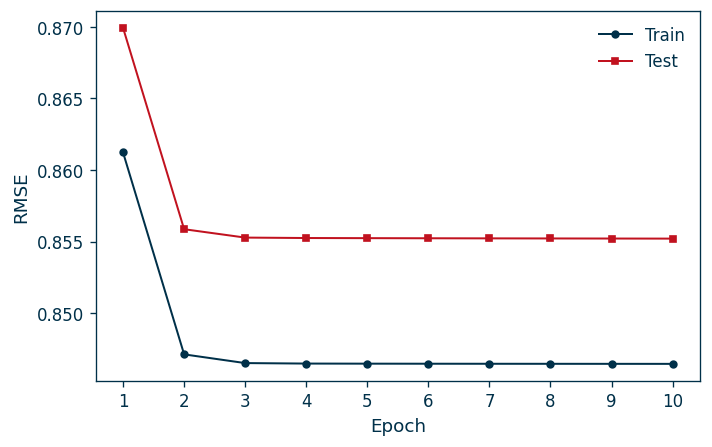

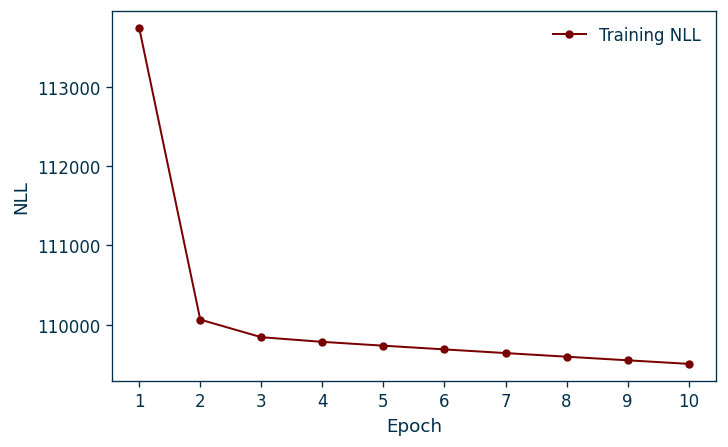

In [35]:
m = BiasOnlyModel(data=M)
m.train(10)

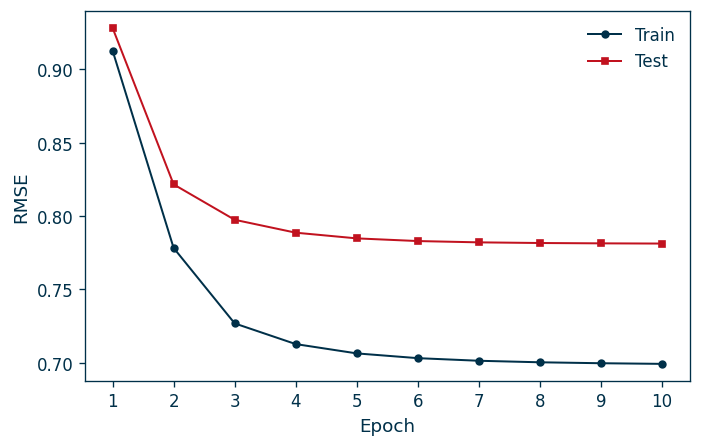

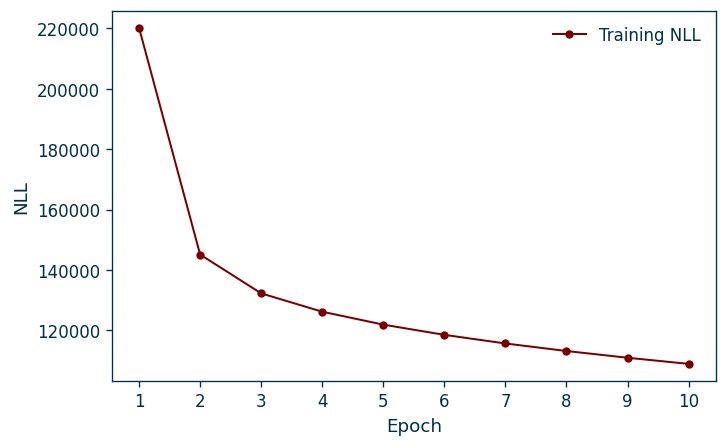

In [30]:
m = FullModel(M)
m.train(10)

In [ ]:
movies = pd.read_csv(r"C:\Users\Lenovo\Downloads\ml-32m\ml-32m\movies.csv")
top_5 = m.create_user_that_likes(1, 5)
result = movies.loc[movies['movieId'].isin(top_5)]
print(result)

       movieId                  title  \
0            1       Toy Story (1995)   
3021      3114     Toy Story 2 (1999)   
4781      4886  Monsters, Inc. (2001)   
14815    78499     Toy Story 3 (2010)   
29990   134853      Inside Out (2015)   

                                                  genres  
0            Adventure|Animation|Children|Comedy|Fantasy  
3021         Adventure|Animation|Children|Comedy|Fantasy  
4781         Adventure|Animation|Children|Comedy|Fantasy  
14815   Adventure|Animation|Children|Comedy|Fantasy|IMAX  
29990  Adventure|Animation|Children|Comedy|Drama|Fantasy  


In [ ]:
def grid_search(data, model_cls, param_grid, epochs=10, seed=0):
    keys = list(param_grid)
    combos = list(itertools.product(*param_grid.values()))
    results = []
    for n, values in enumerate(combos, 1):
        params = dict(zip(keys, values))
        np.random.seed(seed)                             
        model = model_cls(data, **params)
        for _ in range(epochs):
            model.update()                              
        loss, rmse_train, rmse_test = model._calc_loss()
        results.append({**params, "train_rmse": float(rmse_train), "test_rmse": float(rmse_test),
                        "nll": float(loss)})
        print(f"[{n}/{len(combos)}] {params} -> train {rmse_train:.4f}, test {rmse_test:.4f}, "
              f"NLL {loss:,.1f}")
 
    results.sort(key="test_rmse")
    best = {k: results[0][k] for k in keys}
    print(f"\nBest: {best} (test RMSE {results[0]['test_rmse']:.4f}, NLL {results[0]['nll']:,.1f})")
    return best, results


best_b, res_b = grid_search(M, BiasOnlyModel,
                            {"tao": [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1]}, epochs=10)




[1/6] {'tao': 0.0005} -> train 0.8462, test 0.8553, NLL 103,800.3
[2/6] {'tao': 0.001} -> train 0.8462, test 0.8553, NLL 104,476.7
[3/6] {'tao': 0.005} -> train 0.8465, test 0.8552, NLL 109,504.6
[4/6] {'tao': 0.01} -> train 0.8471, test 0.8555, NLL 114,947.5
[5/6] {'tao': 0.05} -> train 0.8561, test 0.8638, NLL 137,985.7
[6/6] {'tao': 0.1} -> train 0.8679, test 0.8753, NLL 145,025.1

Best: {'tao': 0.005} (test RMSE 0.8552, NLL 109,504.6)


In [11]:
best_g, res_g = grid_search(M, FullModel,
                            {"k": [16], "tao": [best_b["tao"]],
                             "gamma": [0.003, 0.01, 0.03, 0.1, 0.3]}, epochs=10)

best, res = grid_search(M, FullModel,
                        {"k": [2, 4, 8, 16, 32], "tao": [best_b["tao"]],
                         "gamma": [best_g["gamma"]]}, epochs=10)

[1/5] {'k': 16, 'tao': 0.005, 'gamma': 0.003} -> train 0.6728, test 0.7911, NLL 73,704.6
[2/5] {'k': 16, 'tao': 0.005, 'gamma': 0.01} -> train 0.6748, test 0.7832, NLL 74,711.3
[3/5] {'k': 16, 'tao': 0.005, 'gamma': 0.03} -> train 0.6797, test 0.7777, NLL 76,602.0
[4/5] {'k': 16, 'tao': 0.005, 'gamma': 0.1} -> train 0.6919, test 0.7739, NLL 80,990.1
[5/5] {'k': 16, 'tao': 0.005, 'gamma': 0.3} -> train 0.7148, test 0.7761, NLL 88,593.8

Best: {'k': 16, 'tao': 0.005, 'gamma': 0.1} (test RMSE 0.7739, NLL 80,990.1)
[1/5] {'k': 2, 'tao': 0.005, 'gamma': 0.1} -> train 0.8035, test 0.8221, NLL 100,589.6
[2/5] {'k': 4, 'tao': 0.005, 'gamma': 0.1} -> train 0.7786, test 0.8075, NLL 95,772.8
[3/5] {'k': 8, 'tao': 0.005, 'gamma': 0.1} -> train 0.7392, test 0.7857, NLL 88,746.6
[4/5] {'k': 16, 'tao': 0.005, 'gamma': 0.1} -> train 0.6919, test 0.7739, NLL 80,990.1
[5/5] {'k': 32, 'tao': 0.005, 'gamma': 0.1} -> train 0.6363, test 0.7820, NLL 72,799.3

Best: {'k': 16, 'tao': 0.005, 'gamma': 0.1} (test

In [ ]:

LAVA, BRICK, DEEP, STEEL = "#780000", "#c1121f", "#003049", "#669bbc"
 
plt.rcParams.update({
    "figure.figsize": (6.5, 4), "figure.dpi": 120, "figure.facecolor": "white",
    "axes.facecolor": "white", "savefig.facecolor": "white", "legend.frameon": False,
    "text.color": DEEP, "axes.labelcolor": DEEP, "xtick.color": DEEP, "ytick.color": DEEP,
    "axes.edgecolor": DEEP, "axes.linewidth": 0.8, "lines.linewidth": 1.2,
})

def _save(name, xlabel, ylabel, save_dir):
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    os.makedirs(save_dir, exist_ok=True)
    plt.savefig(os.path.join(save_dir, name + ".svg"), bbox_inches="tight")
    plt.show()
 
 
def print_dataset_statistics(data):
    user_deg = np.diff(data.user_ptr_train) + np.diff(data.user_ptr_test)
    item_deg = np.diff(data.item_ptr_train) + np.diff(data.item_ptr_test)
    n_users, n_items = int(data.number_of_users), int(data.number_of_items)
    n_train, n_test = len(data.ratings_u_train), len(data.ratings_u_test)
    n_total = n_train + n_test
    cells = n_users * n_items                         
 
    print(f"Matrix size:                {n_users:,} users x {n_items:,} movies = {cells:,} cells")
    print(f"Observed ratings:           {n_total:,}")
    print(f"Ratings / matrix size:      {n_total / cells:.6f}  ({n_total / cells:.4%})")
    print(f"Movie degree (whole data):  max {item_deg.max():,}, min {item_deg.min():,}")
    print(f"User degree  (whole data):  max {user_deg.max():,}, min {user_deg.min():,}")
    print(f"Ratings in training set:    {n_train:,}")
    print(f"Ratings in test set:        {n_test:,}")
 
 
def plot_losses(model, save_dir="figures"):
    epochs = range(1, len(model.RMSE_loss_train) + 1)
 
    plt.figure()
    plt.plot(epochs, model.RMSE_loss_train, color=DEEP, marker="o", ms=4, label="Train")
    plt.plot(epochs, model.RMSE_loss_test, color=BRICK, marker="s", ms=4, label="Test")
    plt.xticks(epochs)
    plt.legend()
    _save("rmse", "Epoch", "RMSE", save_dir)
 
    plt.figure()
    plt.plot(epochs, model.loss_train, color=LAVA, marker="o", ms=4, label="Training NLL")
    plt.xticks(epochs)
    plt.legend()
    _save("nll", "Epoch", "NLL", save_dir)
 
 
def plot_rating_distribution(data, save_dir="figures"):
    train, test = data.ratings_u_train, data.ratings_u_test
    edges = np.arange(0.25, 5.5, 0.5)                
    x = np.arange(10)
 
    plt.figure()
    for i, (label, values, color) in enumerate([("All ratings", np.r_[train, test], DEEP),
                                                ("Train", train, STEEL), ("Test", test, BRICK)]):
        plt.bar(x + (i - 1) * 0.27, np.histogram(values, edges)[0], 0.27,
                color=color, edgecolor=DEEP, label=label)
    plt.xticks(x, np.arange(0.5, 5.5, 0.5))
    plt.gca().yaxis.set_major_formatter("{x:,.0f}")
    plt.legend(loc="upper left")
    _save("rating_distribution", "Rating value", "Number of ratings", save_dir)
 
 
def plot_degree_distributions(data, save_dir="figures"):
    users = np.diff(data.user_ptr_train) + np.diff(data.user_ptr_test)
    movies = np.diff(data.item_ptr_train) + np.diff(data.item_ptr_test)
 
    plt.figure()
    for degrees, marker, color, label in [(users, "o", BRICK, "Users"), (movies, "s", STEEL, "Movies")]:
        d, count = np.unique(degrees, return_counts=True)    # count = how many have degree d
        plt.scatter(d, count, s=18, marker=marker, c=color, edgecolors=DEEP, linewidths=0.5, label=label)
    plt.xscale("log")
    plt.yscale("log")
    plt.legend()
    _save("degree_distributions", "Degree (number of ratings)", "Number of users / movies", save_dir)
 
 
def plot_item_embeddings(model, data, movies_path, top_n=500, save_dir="figures"):
    with open(movies_path, encoding="utf-8") as f:
        next(f)                                              # skip the header line
        movies = {int(r[0]): (r[1], r[2]) for r in csv.reader(f)}   # id -> (title, genres)
 
    top = np.argsort(np.diff(data.item_ptr_train) + np.diff(data.item_ptr_test))[-top_n:]
    pca = PCA(n_components=2)
    xy = pca.fit_transform(model.V[top])                     # centered, so (0, 0) is the mean item
    info = [movies.get(data.index_to_item[i], ("?", "")) for i in top]
 
    kids = np.array(["Animation" in g or "Children" in g for _, g in info])
    horror = np.array(["Horror" in g for _, g in info]) & ~kids
 
    plt.figure(figsize=(7, 5.5))
    plt.axhline(0, color=DEEP, lw=0.8, ls="--", label="Mean item vector (origin)")
    plt.axvline(0, color=DEEP, lw=0.8, ls="--")
    for mask, color, label in [(~(kids | horror), STEEL, "Other genres"),
                               (kids, BRICK, "Animation / Children"), (horror, DEEP, "Horror")]:
        plt.scatter(*xy[mask].T, s=20, c=color, edgecolors=DEEP, linewidths=0.5, label=label)
    for j in {*xy.argmin(axis=0), *xy.argmax(axis=0)}:      # label the 4 extreme movies
        plt.annotate(info[j][0].rsplit(" (", 1)[0][:24], xy[j], xytext=(4, 3),
                     textcoords="offset points", fontsize=7)
    plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
    v = pca.explained_variance_ratio_
    _save("item_embeddings", f"Principal component 1 ({v[0]:.0%} of variance)",
          f"Principal component 2 ({v[1]:.0%} of variance)", save_dir)
 